# Praktikum 1: Klasifikasi Risiko Burnout (High vs Non-High) dengan Neural Network pada Dataset PBL

## Langkah 1: Import Library

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

## Langkah 2: Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')
df_sample, _ = train_test_split(
    df, train_size=10000, stratify=df['Burnout_Risk'], random_state=42
)
print(f"Jumlah data sampel: {len(df_sample)}")

Jumlah data sampel: 10000


## Langkah 3: Preprocessing (Seleksi Fitur & Encoding Label)

In [3]:
num_cols = df_sample.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in ['Person_ID', 'Burnout_Score']]

X_feat = SimpleImputer(strategy='median').fit_transform(df_sample[feature_cols])
# Target biner: 1 untuk High Burnout Risk, 0 untuk Low/Moderate
y_all = (df_sample['Burnout_Risk'] == 'High').astype(int).values
print(f"Dimensi fitur: {X_feat.shape}, Proporsi kelas High (1): {y_all.mean():.4f}")

Dimensi fitur: (10000, 19), Proporsi kelas High (1): 0.1970


## Langkah 4: Split Data Training & Testing

In [4]:
X_train_raw, X_test_raw, y_train_full, y_test = train_test_split(
    X_feat, y_all, test_size=0.2, stratify=y_all, random_state=42
)
print(f"Data training+val: {X_train_raw.shape}, Data testing: {X_test_raw.shape}")

Data training+val: (8000, 19), Data testing: (2000, 19)


## Langkah 5: Normalisasi Fitur

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

## Langkah 6: Split Data Training & Validation

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=42,
)

## Langkah 7: Konversi Label ke Numpy Array

In [7]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test_scaled.shape}")

Train: (6400, 19), Val: (1600, 19), Test: (2000, 19)


## Langkah 8: Membangun Arsitektur Model Neural Network

In [8]:
tf.keras.utils.set_random_seed(42)
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,881 (42.50 KB)

 Trainable params: 10,881 (42.50 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 9: Training Model

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1,
)

Epoch 1/20


  1/200 ━━━━━━━━━━━━━━━━━━━━ 2:35 780ms/step - accuracy: 0.2188 - loss: 0.7448

 37/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8480 - loss: 0.3849    

 74/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8813 - loss: 0.2963

111/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8953 - loss: 0.2568

149/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9021 - loss: 0.2344

... (152 outputs left out)

113/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9618 - loss: 0.0964

152/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9591 - loss: 0.0979

187/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9586 - loss: 0.0978

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9594 - loss: 0.0958 - val_accuracy: 0.9200 - val_loss: 0.1999


## Langkah 10: Evaluasi Model

In [10]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Akurasi Test: {test_acc:.4f}, Test Loss: {test_loss:.4f}")

Akurasi Test: 0.8970, Test Loss: 0.2404


## Langkah 11: Prediksi dan Laporan Klasifikasi serta Visualisasi

In [11]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['Non-High', 'High']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

    Non-High       0.93      0.95      0.94      1606
        High       0.76      0.69      0.73       394

    accuracy                           0.90      2000
   macro avg       0.84      0.82      0.83      2000
weighted avg       0.89      0.90      0.90      2000

Confusion Matrix:
[[1521   85]
 [ 121  273]]


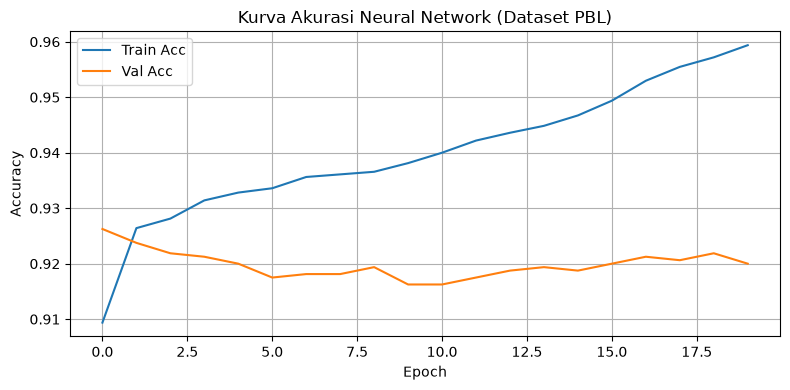

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Kurva Akurasi Neural Network (Dataset PBL)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Langkah 12: Menyimpan Model dan Scaler

In [13]:
model.save('burnout_nn_model.h5')
print("Model berhasil disimpan sebagai: burnout_nn_model.h5")

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan sebagai: scaler.pkl")

Model berhasil disimpan sebagai: burnout_nn_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
